# M13.1 — Diagnósticos de M11 sobre validación

Protocolo: `docs/experiments/M13_1_diagnostics.md` (fijado antes de los resultados).

Este notebook solo lee las salidas de `scripts/m13/m13_1_diagnostics.py` en `$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M13_1_diagnostics/`; no lee X, el HDF5, el npz ni el checkpoint. Solo validación; descriptivo, no selecciona modelos.

En las figuras, los grupos con n < 200 (`sparse`) aparecen rodeados por un círculo negro. Barras: IC 95 % bootstrap (remuestreo dentro de entorno).

In [3]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
OUT = DATA_ROOT / 'results' / 'M11_final_G1_500k' / 'M13_1_diagnostics'

analysis = json.loads((OUT / 'analysis.json').read_text())
a_bins = pd.read_csv(OUT / 'a_bins.csv')
a_cross = pd.read_csv(OUT / 'a_cross.csv')
b_corr = pd.read_csv(OUT / 'b_corr.csv')
c_path = OUT / 'c_filters.csv'
c_filters = pd.read_csv(c_path) if c_path.exists() else None
SNR_ORDER = analysis['settings']['snr_bins']
print(OUT)

/data/vserrano/cbc_pe_data/results/M11_final_G1_500k/M13_1_diagnostics


## Procedencia

In [4]:
for k in ('experiment', 'npz', 'npz_sha256', 'script_sha256', 'contract_identity', 'npz_label_units',
          'n_rows', 'n_environments', 'n_mass1_lt_mass2', 'n_eta_pred_clipped', 'n_outside_snr_bins',
          'n_per_f220_class', 'f220_percentiles_hz', 'reconstruction_max_abs_err'):
    print(f'{k}: {analysis[k]}')
print('part_c:', {k: v for k, v in analysis['part_c'].items() if k != 'block1_readout'})
print('checks passed:')
for c in analysis['checks_passed']:
    print('  -', c)
print(json.dumps(analysis['settings'], indent=1))

experiment: M13.1 CPU diagnostics of M11 on validation (descriptive, exploratory)
npz: /data/vserrano/cbc_pe_data/results/M11_final_G1_500k/m11_final_G1_500k_val_predictions_embeddings.npz
npz_sha256: 586b95f2cb2cfaf150fbdd05760f50f47a95a555451fcb46d89492b7d00ed88b
script_sha256: ab9ae074aed98e6bb0f3f74cb1b43d551c86132619152577cc8a1c2bd7ab25a4
contract_identity: {'version': 'M12.5.2-NPE-v1', 'pinned': {'split_file': '1abf607c44cc4c55ca196de046874137e274c88cf221143cd936d645e97b97d2', 'label_stats_file': 'd0891bf1c130186fb4e7af442e74952a03e4d7d5e0cc240f78d8772e4421855f', 'baseline': '586b95f2cb2cfaf150fbdd05760f50f47a95a555451fcb46d89492b7d00ed88b'}, 'header': {'config_sha256': 'cf9562725bb88ee68b325beb3e44b41bfb5327a6d1a946cd1d9577bab6bd9467', 'manifest_sha256': '544579ef7270675b80caee34cfe440d9b767b02ada3fd5f4de2e8e0f066b864e', 'labels': 'chirp_mass,total_mass,chi_eff', 'detector_order': 'H1,L1,V1', 'input_normalization': 'per_sample_per_detector_zscore', 'input_zscore_epsilon': 1e-06,

In [5]:
def errplot(ax, x, d, col, label=None, **kw):
    v = d[col].to_numpy()
    yerr = np.vstack([v - d[col + '_ci_lo'].to_numpy(), d[col + '_ci_hi'].to_numpy() - v])
    ax.errorbar(x, v, yerr=yerr, capsize=3, marker='o', label=label, **kw)
    sp = d['sparse'].to_numpy(bool)
    if sp.any():
        ax.scatter(np.asarray(x)[sp], v[sp], s=120, facecolors='none', edgecolors='k', zorder=3)


def cross(grouping, lab, snr_bin):
    return a_cross[(a_cross.grouping == grouping) & (a_cross.label == lab) & (a_cross.snr_bin == snr_bin)]

## F1 — Sesgo y RMSE por decil de tau30, una curva por bin de SNR

Lectura HIP-CONTEXTO: a igual SNR, RMSE de chi_eff creciente con tau30 la apoya.

bordes de deciles de tau30 [s]: [0.052 0.079 0.099 0.122 0.151 0.189 0.244 0.325 0.453 0.707 5.892]
snr_bin  [10,15)  [15,20)  [20,25]
group                             
D1          1331     1315     1354
D2          1376     1311     1313
D3          1313     1287     1400
D4          1317     1364     1319
D5          1346     1368     1286
D6          1343     1324     1333
D7          1382     1324     1294
D8          1323     1328     1349
D9          1359     1324     1317
D10         1378     1316     1306


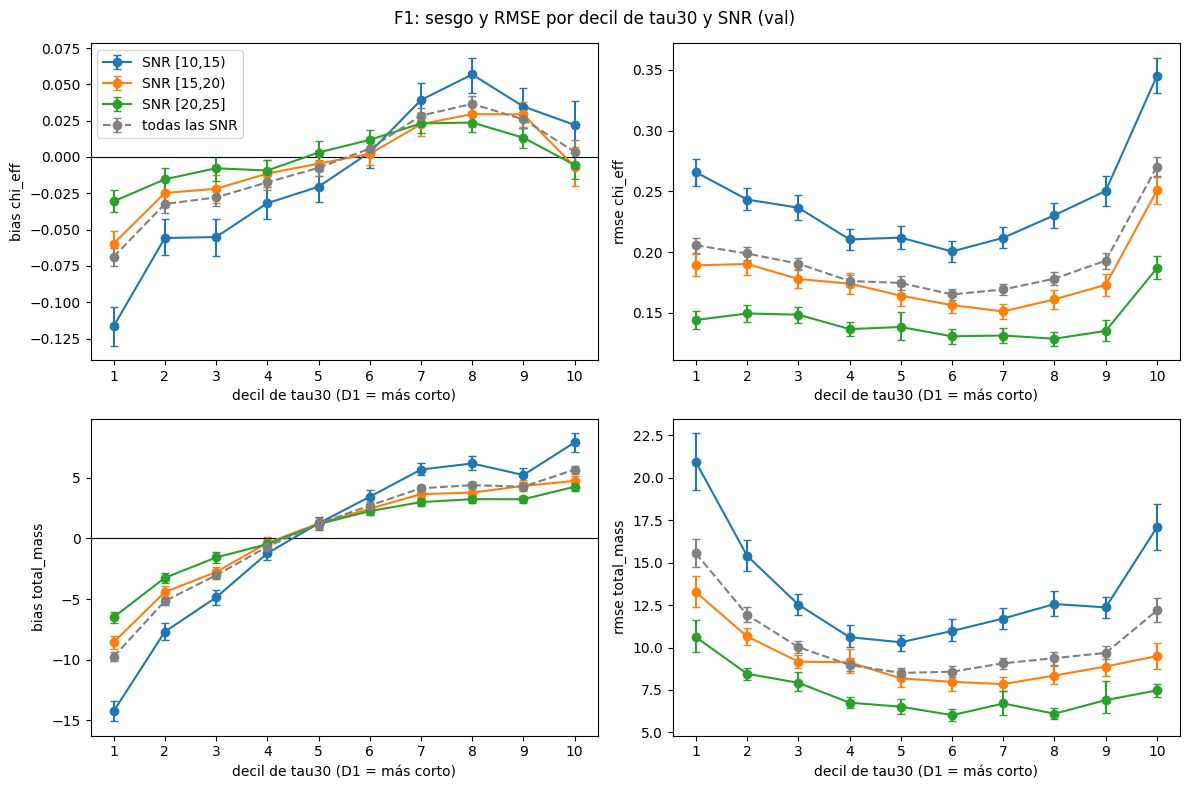

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, lab in enumerate(['chi_eff', 'total_mass']):
    ref = a_bins[(a_bins.grouping == 'tau30_decile') & (a_bins.label == lab)]
    x = np.arange(1, len(ref) + 1)
    for c, col in enumerate(['bias', 'rmse']):
        ax = axes[i, c]
        for s in SNR_ORDER:
            errplot(ax, x, cross('tau30_decile_x_snr', lab, s), col, label='SNR ' + s)
        errplot(ax, x, ref, col, label='todas las SNR', color='0.5', ls='--')
        ax.set(xlabel='decil de tau30 (D1 = más corto)', ylabel=f'{col} {lab}', xticks=x)
        if col == 'bias':
            ax.axhline(0, color='k', lw=0.8)
axes[0, 0].legend()
fig.suptitle('F1: sesgo y RMSE por decil de tau30 y SNR (val)')
fig.tight_layout()
print('bordes de deciles de tau30 [s]:', np.round(analysis['settings']['tau30_decile_edges_s'], 3))
print(a_cross[(a_cross.grouping == 'tau30_decile_x_snr') & (a_cross.label == 'chi_eff')]
      .pivot(index='group', columns='snr_bin', values='n').reindex(ref['group']))

## F2 — Por clase de f220 × SNR

Lectura HIP-BANDA-ALTA (parte a): escalón de error en `256-512` frente a `<256` a igual SNR. La clase de f220 está correlacionada con la masa.

snr_bin  [10,15)  [15,20)  [20,25]
group                             
<256       10248    10191    10241
256-512     2652     2508     2470
>512         568      562      560


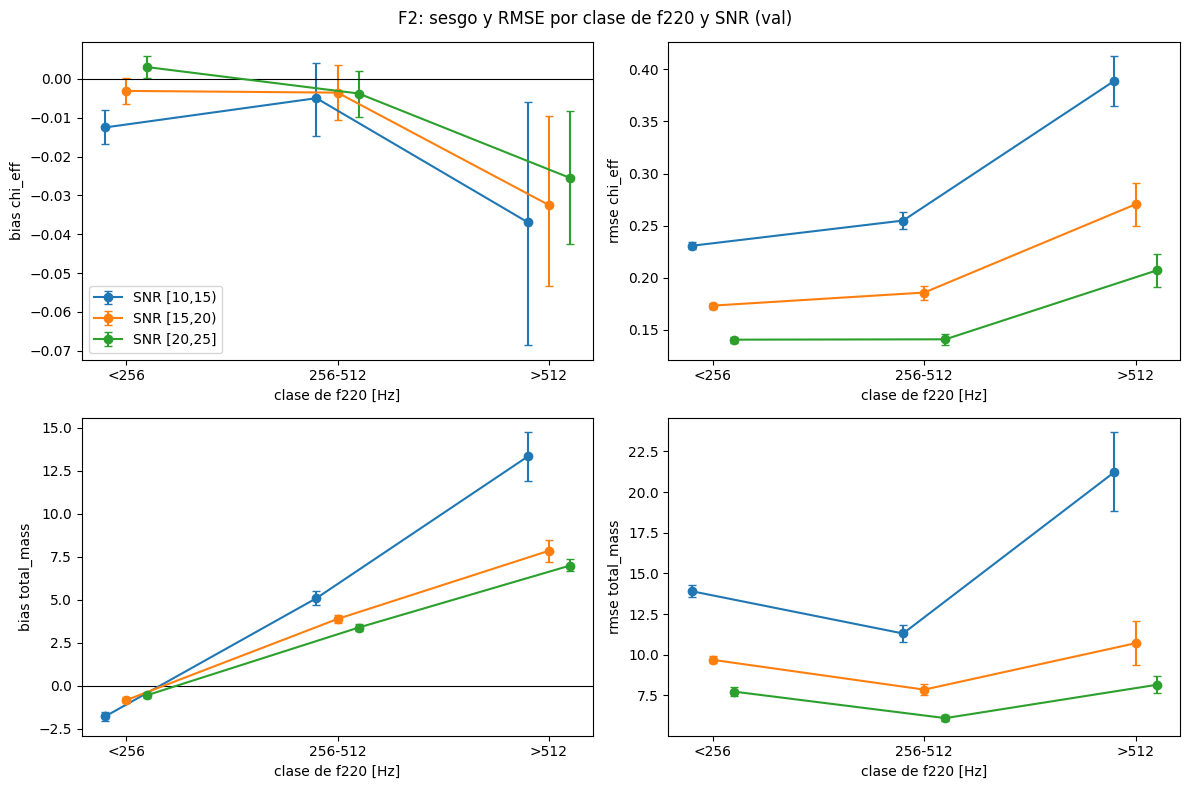

In [7]:
classes = list(a_bins.loc[a_bins.grouping == 'f220_class', 'group'].unique())
x = np.arange(len(classes))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, lab in enumerate(['chi_eff', 'total_mass']):
    for c, col in enumerate(['bias', 'rmse']):
        ax = axes[i, c]
        for k, s in enumerate(SNR_ORDER):
            errplot(ax, x + 0.1 * (k - 1), cross('f220_class_x_snr', lab, s), col, label='SNR ' + s)
        ax.set(xticks=x, xticklabels=classes, xlabel='clase de f220 [Hz]', ylabel=f'{col} {lab}')
        if col == 'bias':
            ax.axhline(0, color='k', lw=0.8)
axes[0, 0].legend()
fig.suptitle('F2: sesgo y RMSE por clase de f220 y SNR (val)')
fig.tight_layout()
print(a_cross[(a_cross.grouping == 'f220_class_x_snr') & (a_cross.label == 'chi_eff')]
      .pivot(index='group', columns='snr_bin', values='n').reindex(classes))

## F3 — Por cociente de masas q

,grouping,group,label,n,sparse,bias,bias_ci_lo,bias_ci_hi,rmse,rmse_ci_lo,rmse_ci_hi
30,f220_class,<256,chirp_mass,30680,False,-0.357956,-0.432801,-0.282978,6.405349,6.304799,6.504879
31,f220_class,<256,total_mass,30680,False,-1.052812,-1.176984,-0.933915,10.755651,10.556143,10.969946
32,f220_class,<256,chi_eff,30680,False,-0.004210,-0.006258,-0.002020,0.185170,0.183316,0.187221
33,f220_class,256-512,chirp_mass,7630,False,1.246869,1.189831,1.303904,2.798748,2.664592,2.944766
34,f220_class,256-512,total_mass,7630,False,4.140825,3.961605,4.310793,8.759608,8.503459,9.033096
35,f220_class,256-512,chi_eff,7630,False,-0.004128,-0.008533,0.000133,0.200758,0.196197,0.205282
36,f220_class,>512,chirp_mass,1690,False,2.736625,2.544423,2.925781,4.853029,4.247258,5.466055
37,f220_class,>512,total_mass,1690,False,9.400392,8.846338,9.944718,14.550085,13.287396,15.828842
38,f220_class,>512,chi_eff,1690,False,-0.031672,-0.046349,-0.018077,0.299004,0.286643,0.311442
39,q_bin,"[1,1.5)",chirp_mass,14843,False,-2.865678,-2.955858,-2.779482,6.137315,5.972009,6.309085


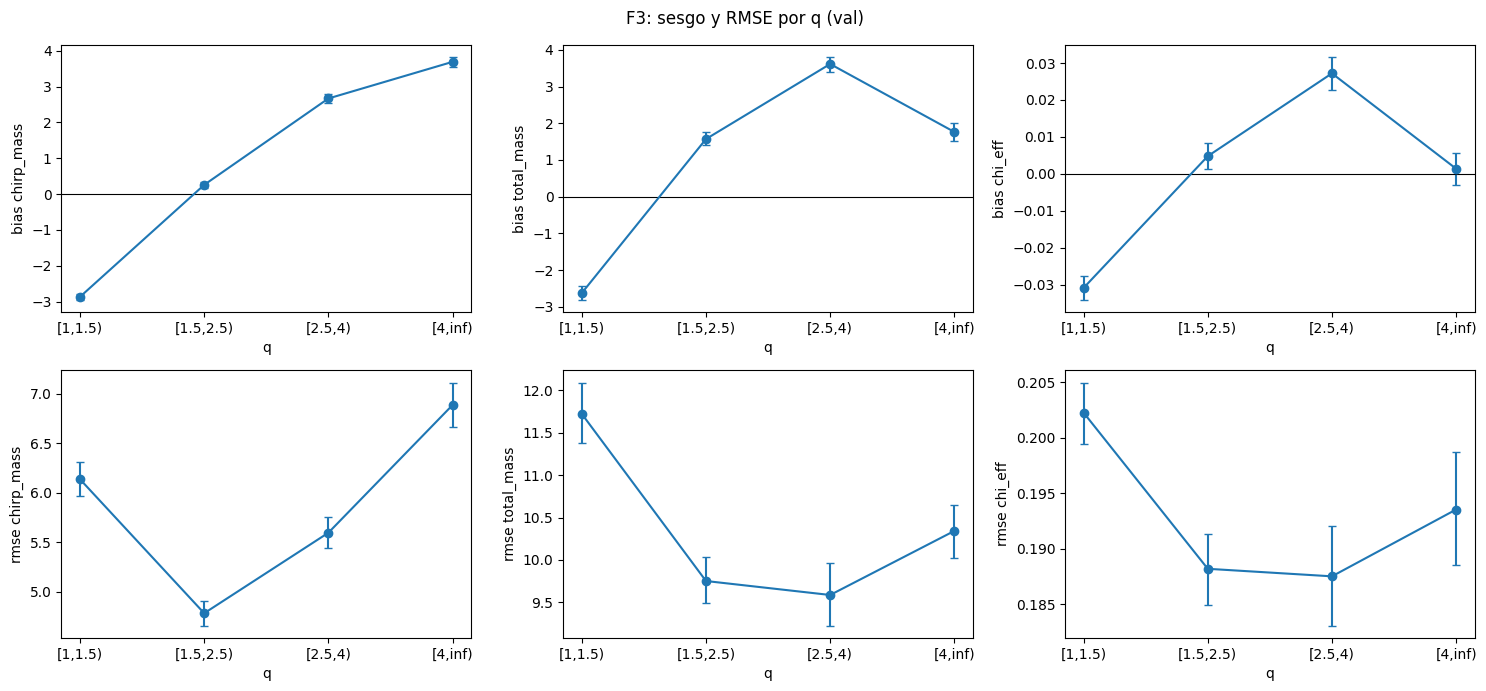

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, lab in enumerate(analysis['labels']):
    d = a_bins[(a_bins.grouping == 'q_bin') & (a_bins.label == lab)]
    x = np.arange(len(d))
    for c, col in enumerate(['bias', 'rmse']):
        ax = axes[c, j]
        errplot(ax, x, d, col)
        ax.set(xticks=x, xticklabels=d['group'], xlabel='q', ylabel=f'{col} {lab}')
        if col == 'bias':
            ax.axhline(0, color='k', lw=0.8)
fig.suptitle('F3: sesgo y RMSE por q (val)')
fig.tight_layout()
cols = ['grouping', 'group', 'label', 'n', 'sparse', 'bias', 'bias_ci_lo', 'bias_ci_hi', 'rmse', 'rmse_ci_lo', 'rmse_ci_hi']
a_bins.loc[a_bins.grouping.isin(['q_bin', 'snr_bin', 'f220_class']), cols]

## F4 — Residuos (r_eta, r_chi): histograma 2D y correlaciones

Lectura de degeneración: |Spearman(r_eta, r_chi)| ≥ 0.3 global, o mayor en el tercil de Mc bajo.

{'spearman_global': 0.18928946970172913, 'spearman_mc_terciles': [-0.06553666754210968, 0.36620054697618243, 0.33056931647163146], 'abs_global_ge_0_3': False, 'low_mc_abs_exceeds_global': False, 'low_mc_abs_largest_tercile': False}


,grouping,group,lo,hi,sparse,n,pearson,spearman,slope,intercept,r2
0,global,all,NaN,NaN,False,40000,0.141450,0.189289,0.915371,-0.004345,0.020008
1,mc_tercile,T1,4.581474,27.730182,False,13333,-0.074666,-0.065537,-0.394608,0.025377,0.005575
2,mc_tercile,T2,27.730182,44.970024,False,13333,0.360922,0.366201,2.300896,-0.000072,0.130265
3,mc_tercile,T3,44.970024,78.012186,False,13334,0.308694,0.330569,3.531873,-0.009422,0.095292
4,f220_class,<256,0.000000,256.000000,False,30680,0.328210,0.334916,2.193969,-0.007224,0.107722
5,f220_class,256-512,256.000000,512.000000,False,7630,-0.239553,-0.160785,-1.405292,-0.012771,0.057386
6,f220_class,>512,512.000000,inf,False,1690,-0.377717,-0.351180,-3.000333,-0.101508,0.142670


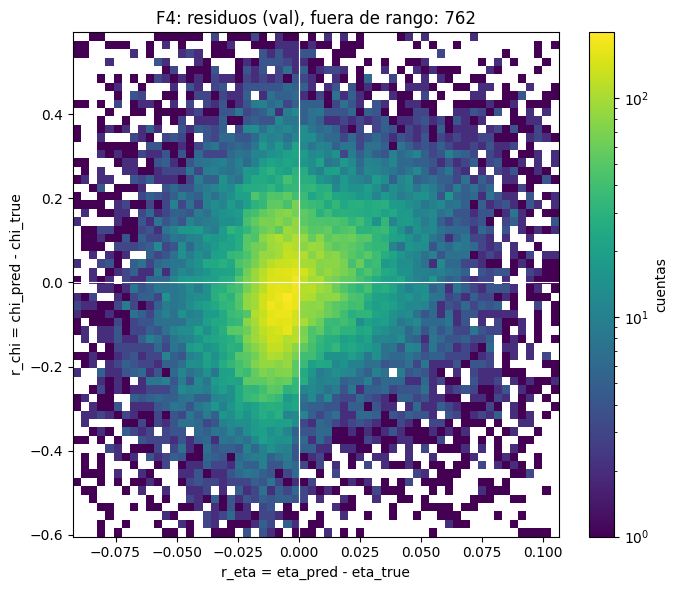

In [9]:
h = analysis['b_hist2d']
counts = np.array(h['counts'], dtype=float).T  # histogram2d is (x, y); pcolormesh wants (y, x)
fig, ax = plt.subplots(figsize=(7, 6))
mesh = ax.pcolormesh(h['x_edges'], h['y_edges'], np.ma.masked_where(counts == 0, counts),
                     norm=LogNorm(), shading='flat')
fig.colorbar(mesh, ax=ax, label='cuentas')
ax.axhline(0, color='w', lw=0.8)
ax.axvline(0, color='w', lw=0.8)
ax.set(xlabel='r_eta = eta_pred - eta_true', ylabel='r_chi = chi_pred - chi_true',
       title=f'F4: residuos (val), fuera de rango: {h["n_outside"]}')
fig.tight_layout()
print(analysis['degeneracy_readout'])
b_corr

## F5 — Fracciones de energía por banda de los kernels de block1 y block2

block1: entrada a 4096 Hz; block2: entrada a 2048 Hz. Lectura HIP-BANDA-ALTA (parte c): menos del 10 % de los kernels de block1 con más del 30 % de su energía por encima de 256 Hz. Respuesta lineal de cada kernel aislado (sin normalización, no linealidades ni aliasing).

{'n_kernels': 48, 'n_frac_above_256_gt_0_3': 42, 'fraction': 0.875, 'fraction_lt_0_10': False}


layer                 block1.conv  block2.conv   block3.conv
frac_0_256     count    48.000000   512.000000  2.048000e+03
               mean      0.204852     0.493869  7.090119e-01
               std       0.318705     0.217485  1.612156e-01
               min       0.000230     0.006741  1.148429e-01
               25%       0.002249     0.306450  6.066707e-01
               50%       0.008990     0.519898  7.326001e-01
               75%       0.337025     0.661527  8.372030e-01
               max       0.891416     0.939899  9.825843e-01
frac_256_512   count    48.000000   512.000000  2.048000e+03
               mean      0.068941     0.277029  2.907347e-01
               std       0.125458     0.146729  1.610735e-01
               min       0.000126     0.019171  1.741122e-02
               25%       0.002736     0.171621  1.625428e-01
               50%       0.014210     0.252405  2.673240e-01
               75%       0.045604     0.364666  3.932814e-01
               max       0.508855     0.869171  8.849600e-01
frac_512_nyq   count    48.000000   512.000000  2.048000e+03
               mean      0.726207     0.229101  2.533734e-04
               std       0.371747     0.161425  3.888450e-04
               min       0.076158     0.015008  8.531326e-12
               25%       0.268694     0.101191  1.972281e-05
               50%       0.977233     0.193112  1.036563e-04
               75%       0.995093     0.323880  3.203634e-04
               max       0.999542     0.791252  3.201398e-03
frac_above_256 count    48.000000   512.000000  2.048000e+03
               mean      0.795148     0.506131  2.909881e-01
               std       0.318705     0.217485  1.612156e-01
               min       0.108584     0.060101  1.741570e-02
               25%       0.662975     0.338473  1.627970e-01
               50%       0.991010     0.480102  2.673999e-01
               75%       0.997751     0.693550  3.933293e-01
               max       0.999770     0.993259  8.851571e-01

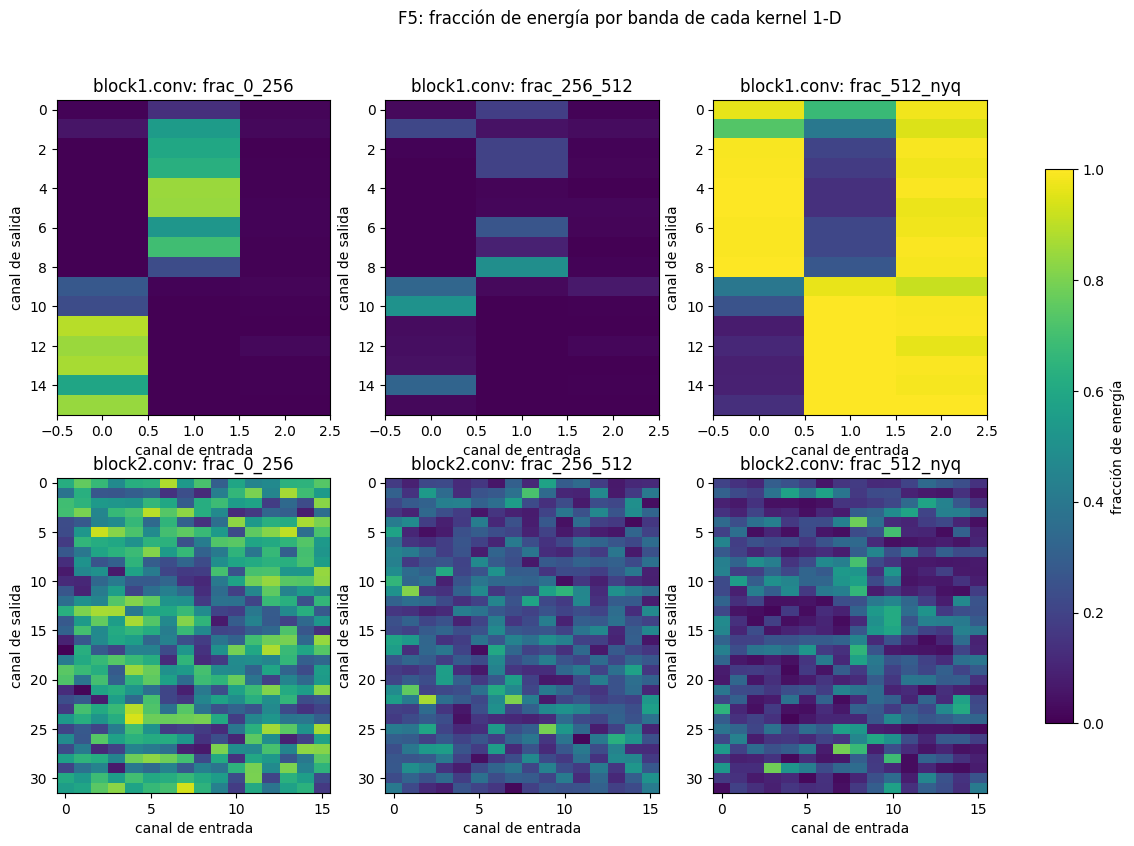

In [10]:
if c_filters is None:
    print('Parte (c) omitida:', analysis['part_c'])
else:
    bands = ['frac_0_256', 'frac_256_512', 'frac_512_nyq']
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for i, layer in enumerate(['block1.conv', 'block2.conv']):
        d = c_filters[c_filters.layer == layer]
        for k, b in enumerate(bands):
            m = d.pivot(index='out_channel', columns='in_channel', values=b).to_numpy()
            im = axes[i, k].imshow(m, aspect='auto', vmin=0, vmax=1, cmap='viridis', interpolation='nearest')
            axes[i, k].set(title=f'{layer}: {b}', xlabel='canal de entrada', ylabel='canal de salida')
    fig.colorbar(im, ax=axes, shrink=0.8, label='fracción de energía')
    fig.suptitle('F5: fracción de energía por banda de cada kernel 1-D')
    print(analysis['part_c']['block1_readout'])
    display(c_filters.groupby('layer')[bands + ['frac_above_256']].describe().T)

## Conclusiones M13.1 (26-10-2026)

Descriptivo, sobre val (40 000 filas), con los grupos definidos sobre las etiquetas verdaderas. IC 95 % por bootstrap remuestreando dentro de cada entorno.

### Resultados verificados
1. **χ_eff frente a τ (F1):** RMSE en U. D1 ≈ 0,205 (pesados), mínimo en D6–D8 ≈ 0,165, D10 (τ > 0,7 s) ≈ 0,27, en los tres rangos de SNR (a SNR 20–25: 0,13 → 0,19). El sesgo de χ_eff va de −0,07 en D1 (−0,12 a SNR 10–15) a +0,03–0,04 en D7–D9. La masa total va de −9,8 M☉ en D1 a +5,6 M☉ en D10.
2. **Clase de f220 (F2):** RMSE de χ_eff (SNR 10–15 / 15–20 / 20–25) de 0,231/0,173/0,140 (<256 Hz), 0,255/0,186/0,141 (256–512 Hz) y 0,389/0,271/0,207 (>512 Hz). Masa total en >512 Hz: sesgo de +13,4/+7,9/+7,0 M☉. Sin escalón entre <256 y 256–512 Hz; salto grande en >512 Hz.
3. **Degeneración (F4):** Spearman(r_η, r_χ) = 0,19 global; por tercil de 𝓜, −0,07/0,37/0,33; por clase de f220, 0,33/−0,16/−0,35; R² ≤ 0,14. η estimado como (𝓜/M)^{5/3} es ruidoso (62 valores recortados).
4. **Filtros (F5):** 42/48 kernels de block1 con más del 30 % de energía por encima de 256 Hz (mediana por encima de 512 Hz: 0,98). block2: 0,28 en 256–512 Hz y 0,23 en 512–1024 Hz. block3: 0,29 en 256–512 Hz.

### Lecturas fijadas
- **HIP-CONTEXTO:** compatible (el RMSE de χ_eff sube en D10 a igual SNR), pero no concluyente. La degeneración q–χ_eff es físicamente más fuerte en sistemas ligeros (Ng et al. 2018). Decide M13.2a.
- **HIP-BANDA-ALTA:** no apoyada. Sin escalón en 256–512 Hz (parte a), y la primera capa no descarta la banda (parte c: 87,5 % de los kernels por encima del umbral).
- **Degeneración:** criterio no cumplido (|Spearman global| < 0,3, y no mayor en 𝓜 bajo).

### Hipótesis (no verificadas)
- El salto en la clase >512 Hz es compatible con que falte el ringdown en los datos (HIP-DATOS-BANDA), mezclado con masa baja, señales largas y el borde del prior. Lo decidirá G1 frente a G2.
- El sesgo de χ_eff por masa tiene el mismo signo que el de la masa total (pesados: ambos por debajo; ligeros: ambos por encima). Posible herencia de la contracción de M a través de la frecuencia de la fusión y el ringdown (∝ F(χ)/M). Coherente con la correlación de residuos masa total–χ_eff = 0,58.
- Los kernels de block1 aplicados a V1 son casi todos de alta frecuencia: posible atenuación de la banda útil de V1.
- **Comprobación posterior (26-10):** Spearman(residuo de M, residuo de χ_eff) = 0,64 global y 0,64–0,70 en cada decil de τ. Los sesgos medios por decil van juntos (M de −9,8 a +5,7 M☉; χ_eff de −0,069 a +0,037, salvo D10 ≈ 0). Apoya que el sesgo de χ_eff por masa se hereda de la contracción de la masa total. Predicción: corregir esa contracción (M13.3) debería reducir parte del sesgo de χ_eff.

### Limitaciones
Descriptivo; la clase de f220 y τ están fuertemente correlacionadas con la masa; los ajustes de f220 tienen errores de pocos por ciento (a_f recortado a ±0,998); la fracción de energía de los kernels no es su ganancia absoluta sobre los datos.